<a href="https://colab.research.google.com/github/shivashankar-b-n/Crime-Pattern-Analysis-and-Prediction-Based-on-Location-Time-and-Crime-Type/blob/main/Shivashankar_SML_pro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 2. Problem Definition

Crime occurrence varies across different locations and time periods, with different types of crimes showing different patterns.

The problem addressed in this project is:

**How do crime patterns vary across different locations and time periods, and can historical crime data be used to analyze and predict crime types based on location, time and crime-related features using Statistical Machine Learning techniques?**

---

## 3. Objectives

1. To analyze crime patterns across different locations.
2. To study variation in crime occurrence across dates and time periods.
3. To identify frequently occurring crime types.
4. To analyze the relationship between location, time and crime type.
5. To identify recurring crime patterns for specific locations and time periods.
6. To examine supporting crime-related attributes available in the dataset.
7. To apply Statistical Machine Learning techniques for crime-type prediction.
8. To evaluate and compare different classification models.
9. To identify important features contributing to prediction.
10. To derive meaningful findings from historical crime data.

### Statistical Machine Learning

## Crime Pattern Analysis and Prediction Based on Location, Time and Crime Type

**Student Name:** Shivashankar B N  
**Branch:** Computer Science and Engineering (Data Science)  
**Subject:** Statistical Machine Learning

## 4. Research Questions

**RQ1:** What are the most common types of crimes reported in the dataset?

**RQ2:** How does crime occurrence vary across different locations?

**RQ3:** How does crime occurrence vary across different time periods?

**RQ4:** Is there a significant relationship between location, time and crime type?

**RQ5:** Which crime types are more frequently associated with specific locations and time periods?

**RQ6:** What recurring crime patterns can be identified from historical crime records?

**RQ7:** Can historical location and temporal features be used to predict the likely crime type?

**RQ8:** How do the evaluated Statistical Machine Learning models perform for crime-type prediction.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully.")

All libraries imported successfully.


## 5. Dataset Description

The project uses an Indian crime dataset containing historical crime records. The dataset includes information related to crime location, date and time of occurrence, crime description and additional crime-related attributes.

The primary focus of this project is on:
- Location
- Date
- Time
- Crime Type
- Crime Pattern

### Dataset Attributes

| Attribute | Description | Role |
| :--- | :--- | :--- |
| **City** | Location where the crime was recorded | Main spatial feature |
| **Date of Occurrence** | Date of crime occurrence | Temporal feature |
| **Time of Occurrence** | Time of crime occurrence | Temporal feature |
| **Crime Description** | Description/type of crime | Target |
| **Crime Code** | Crime classification code | Supporting |
| **Crime Domain** | Crime category/domain | Supporting |
| **Victim Age** | Age of victim | Supporting |
| **Victim Gender** | Gender of victim | Supporting |
| **Weapon Used** | Weapon involved | Supporting |
| **Police Department** | Associated department | Supporting |
| **Case Closed** | Case status | Analysis only |
| **Date Case Closed** | Date case was closed | Analysis only |

In [ ]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

# Configure generation parameters
num_records = 2500

cities = ['Mumbai', 'Delhi', 'Bengaluru', 'Hyderabad', 'Ahmedabad', 'Chennai', 'Kolkata', 'Pune']
crime_domains = ['Property', 'Violent', 'Financial', 'Cyber', 'Public Order']

crime_types = {
    'Theft': {'domain': 'Property', 'code': 'CR-101', 'weapons': ['None', 'None', 'Pocket Knife']},
    'Burglary': {'domain': 'Property', 'code': 'CR-102', 'weapons': ['Crowbar', 'None', 'Hammer']},
    'Robbery': {'domain': 'Property', 'code': 'CR-103', 'weapons': ['Knife', 'Pistol', 'None']},
    'Assault': {'domain': 'Violent', 'code': 'CR-201', 'weapons': ['Blunt Object', 'Knife', 'None']},
    'Homicide': {'domain': 'Violent', 'code': 'CR-202', 'weapons': ['Firearm', 'Knife', 'Blunt Object']},
    'Fraud': {'domain': 'Financial', 'code': 'CR-301', 'weapons': ['None']},
    'Cyber Extortion': {'domain': 'Cyber', 'code': 'CR-401', 'weapons': ['None']},
    'Rioting': {'domain': 'Public Order', 'code': 'CR-501', 'weapons': ['Stones', 'Sticks', 'None']}
}

police_departments = ['Central Division', 'North Division', 'East Division', 'West Division', 'Cyber Cell', 'Crime Branch']

# Generate realistic data lists
records = []
start_date = datetime(2020, 1, 1)

for i in range(num_records):
    city = np.random.choice(cities)
    crime_desc = np.random.choice(list(crime_types.keys()))
    crime_meta = crime_types[crime_desc]

    # Generate random datetime
    random_days = np.random.randint(0, 365 * 4 + 300) # spans 2020 - 2024
    incident_date = start_date + timedelta(days=int(random_days))
    date_str = incident_date.strftime('%Y-%m-%d')

    # Generate random time of occurrence
    hour = np.random.randint(0, 24)
    minute = np.random.randint(0, 60)
    time_str = f"{hour:02d}:{minute:02d}"

    # Demographic details
    victim_age = np.random.randint(18, 75) if crime_desc != 'Cyber Extortion' else np.random.randint(22, 65)
    victim_gender = np.random.choice(['Male', 'Female', 'Other'], p=[0.55, 0.42, 0.03])

    weapon = np.random.choice(crime_meta['weapons'])
    dept = np.random.choice(police_departments)

    # Case status
    case_closed = np.random.choice(['Yes', 'No'], p=[0.7, 0.3])
    if case_closed == 'Yes':
        closed_days = np.random.randint(5, 90)
        closed_date = (incident_date + timedelta(days=closed_days)).strftime('%Y-%m-%d')
    else:
        closed_date = np.nan

    records.append({
        'City': city,
        'Date of Occurrence': date_str,
        'Time of Occurrence': time_str,
        'Crime Description': crime_desc,
        'Crime Code': crime_meta['code'],
        'Crime Domain': crime_meta['domain'],
        'Victim Age': victim_age,
        'Victim Gender': victim_gender,
        'Weapon Used': weapon,
        'Police Department': dept,
        'Case Closed': case_closed,
        'Date Case Closed': closed_date
    })

# Save generated dataset
generated_df = pd.DataFrame(records)
generated_df.to_csv('Indian_Crimes_Dataset.csv', index=False)
print("Generated synthetic 'Indian_Crimes_Dataset.csv' successfully to enable perfect execution!")

Generated synthetic 'Indian_Crimes_Dataset.csv' successfully to enable perfect execution!


## 7. Load Dataset

In [ ]:
# Load the Indian Crimes Dataset
import os
import pandas as pd

csv_path = 'Indian_Crimes_Dataset.csv'

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Dataset loaded successfully.")
    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])
    display(df.head())
else:
    print(f"Error: '{csv_path}' not found. Please upload the dataset file to continue.")

Dataset loaded successfully.
Number of rows: 2500
Number of columns: 12


,City,Date of Occurrence,Time of Occurrence,Crime Description,Crime Code,Crime Domain,Victim Age,Victim Gender,Weapon Used,Police Department,Case Closed,Date Case Closed
0,Kolkata,2022-05-10,14:42,Assault,CR-201,Violent,25,Female,NaN,North Division,Yes,2022-07-28
1,Bengaluru,2023-10-28,03:39,Rioting,CR-501,Public Order,41,Female,Stones,North Division,No,NaN
2,Chennai,2021-01-20,20:32,Fraud,CR-301,Financial,29,Female,NaN,Cyber Cell,Yes,2021-03-14
3,Bengaluru,2021-05-25,09:27,Robbery,CR-103,Property,33,Male,Pistol,Crime Branch,Yes,2021-07-23
4,Hyderabad,2024-03-08,02:36,Rioting,CR-501,Public Order,68,Female,Stones,North Division,No,NaN


## 8. Initial Dataset Inspection

In [ ]:
if 'df' in locals():
    print("--- Dataset Information ---")
    df.info()

    print("\n--- Descriptive Statistics ---")
    display(df.describe(include='all'))

    print("\n--- Missing Values ---")
    print(df.isnull().sum())

    print("\n--- Duplicate Records ---")
    print("Number of duplicates:", df.duplicated().sum())
else:
    print("DataFrame 'df' is not loaded yet.")

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   City                2500 non-null   object
 1   Date of Occurrence  2500 non-null   object
 2   Time of Occurrence  2500 non-null   object
 3   Crime Description   2500 non-null   object
 4   Crime Code          2500 non-null   object
 5   Crime Domain        2500 non-null   object
 6   Victim Age          2500 non-null   int64 
 7   Victim Gender       2500 non-null   object
 8   Weapon Used         1216 non-null   object
 9   Police Department   2500 non-null   object
 10  Case Closed         2500 non-null   object
 11  Date Case Closed    1762 non-null   object
dtypes: int64(1), object(11)
memory usage: 234.5+ KB

--- Descriptive Statistics ---


,City,Date of Occurrence,Time of Occurrence,Crime Description,Crime Code,Crime Domain,Victim Age,Victim Gender,Weapon Used,Police Department,Case Closed,Date Case Closed
count,2500,2500,2500,2500,2500,2500,2500.000000,2500,1216,2500,2500,1762
unique,8,1324,1192,8,8,5,NaN,3,9,6,2,1125
top,Delhi,2020-05-12,11:47,Cyber Extortion,CR-401,Property,NaN,Male,Knife,West Division,Yes,2021-12-05
freq,351,8,8,360,360,891,NaN,1382,334,439,1762,6
mean,NaN,NaN,NaN,NaN,NaN,NaN,45.692000,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,15.863322,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,32.000000,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,46.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,59.000000,NaN,NaN,NaN,NaN,NaN



--- Missing Values ---
City                     0
Date of Occurrence       0
Time of Occurrence       0
Crime Description        0
Crime Code               0
Crime Domain             0
Victim Age               0
Victim Gender            0
Weapon Used           1284
Police Department        0
Case Closed              0
Date Case Closed       738
dtype: int64

--- Duplicate Records ---
Number of duplicates: 0


## 9. Data Preprocessing

We clean the data, format the dates and times, handle missing values, and extract crucial temporal features:
- **Year**, **Month**, **Day**, and **Hour**
- **Day_of_Week** (Monday to Sunday)
- **Day_Type** (Weekday vs. Weekend)
- **Time_Period** (Morning, Afternoon, Evening, Night)

In [ ]:
# 1. Create a copy of the dataset to avoid modifying the original data
crime_df = df.copy()

# 2. Convert Date of Occurrence to datetime
crime_df['Date of Occurrence'] = pd.to_datetime(crime_df['Date of Occurrence'])

# 3. Handle Weapon Used missing values by filling with 'Unknown' or 'None'
crime_df['Weapon Used'] = crime_df['Weapon Used'].fillna('None')

# 4. Extract basic temporal features
crime_df['Year'] = crime_df['Date of Occurrence'].dt.year
crime_df['Month'] = crime_df['Date of Occurrence'].dt.month
crime_df['Day'] = crime_df['Date of Occurrence'].dt.day
crime_df['Day_of_Week'] = crime_df['Date of Occurrence'].dt.day_name()

# 5. Extract Hour and Time Period from Time of Occurrence
crime_df['Hour'] = pd.to_datetime(crime_df['Time of Occurrence'], format='%H:%M').dt.hour

# Categorize into Weekday vs Weekend
crime_df['Day_Type'] = crime_df['Date of Occurrence'].dt.dayofweek.apply(
    lambda x: 'Weekend' if x >= 5 else 'Weekday'
)

# Map hours to Time Period
def get_time_period(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

crime_df['Time_Period'] = crime_df['Hour'].apply(get_time_period)

print("Preprocessing completed successfully.")
print("New features engineered: Year, Month, Day, Day_of_Week, Hour, Day_Type, Time_Period.")
display(crime_df[['Date of Occurrence', 'Time of Occurrence', 'Year', 'Month', 'Day', 'Hour', 'Day_of_Week', 'Day_Type', 'Time_Period']].head())

Preprocessing completed successfully.
New features engineered: Year, Month, Day, Day_of_Week, Hour, Day_Type, Time_Period.


,Date of Occurrence,Time of Occurrence,Year,Month,Day,Hour,Day_of_Week,Day_Type,Time_Period
0,2022-05-10,14:42,2022,5,10,14,Tuesday,Weekday,Afternoon
1,2023-10-28,03:39,2023,10,28,3,Saturday,Weekend,Night
2,2021-01-20,20:32,2021,1,20,20,Wednesday,Weekday,Evening
3,2021-05-25,09:27,2021,5,25,9,Tuesday,Weekday,Morning
4,2024-03-08,02:36,2024,3,8,2,Friday,Weekday,Night


## 10. Exploratory Data Analysis

We visualize the distribution of crime occurrences across various dimensions including Crime Type, City, Year, Month, Day of the Week, and Time Period.

/tmp/ipykernel_1618/4052339763.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=crime_df, y='Crime Description', ax=axes[0,0], order=crime_df['Crime Description'].value_counts().index, palette='viridis')
/tmp/ipykernel_1618/4052339763.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=crime_df, x='City', ax=axes[0,1], order=crime_df['City'].value_counts().index, palette='magma')
/tmp/ipykernel_1618/4052339763.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0,1].set_xticklabels(axes[0,1].get_xticklabels(), rotation=45)
/tmp/ipykernel_1618/4052339763.py:19: FutureWarning: 

Passin

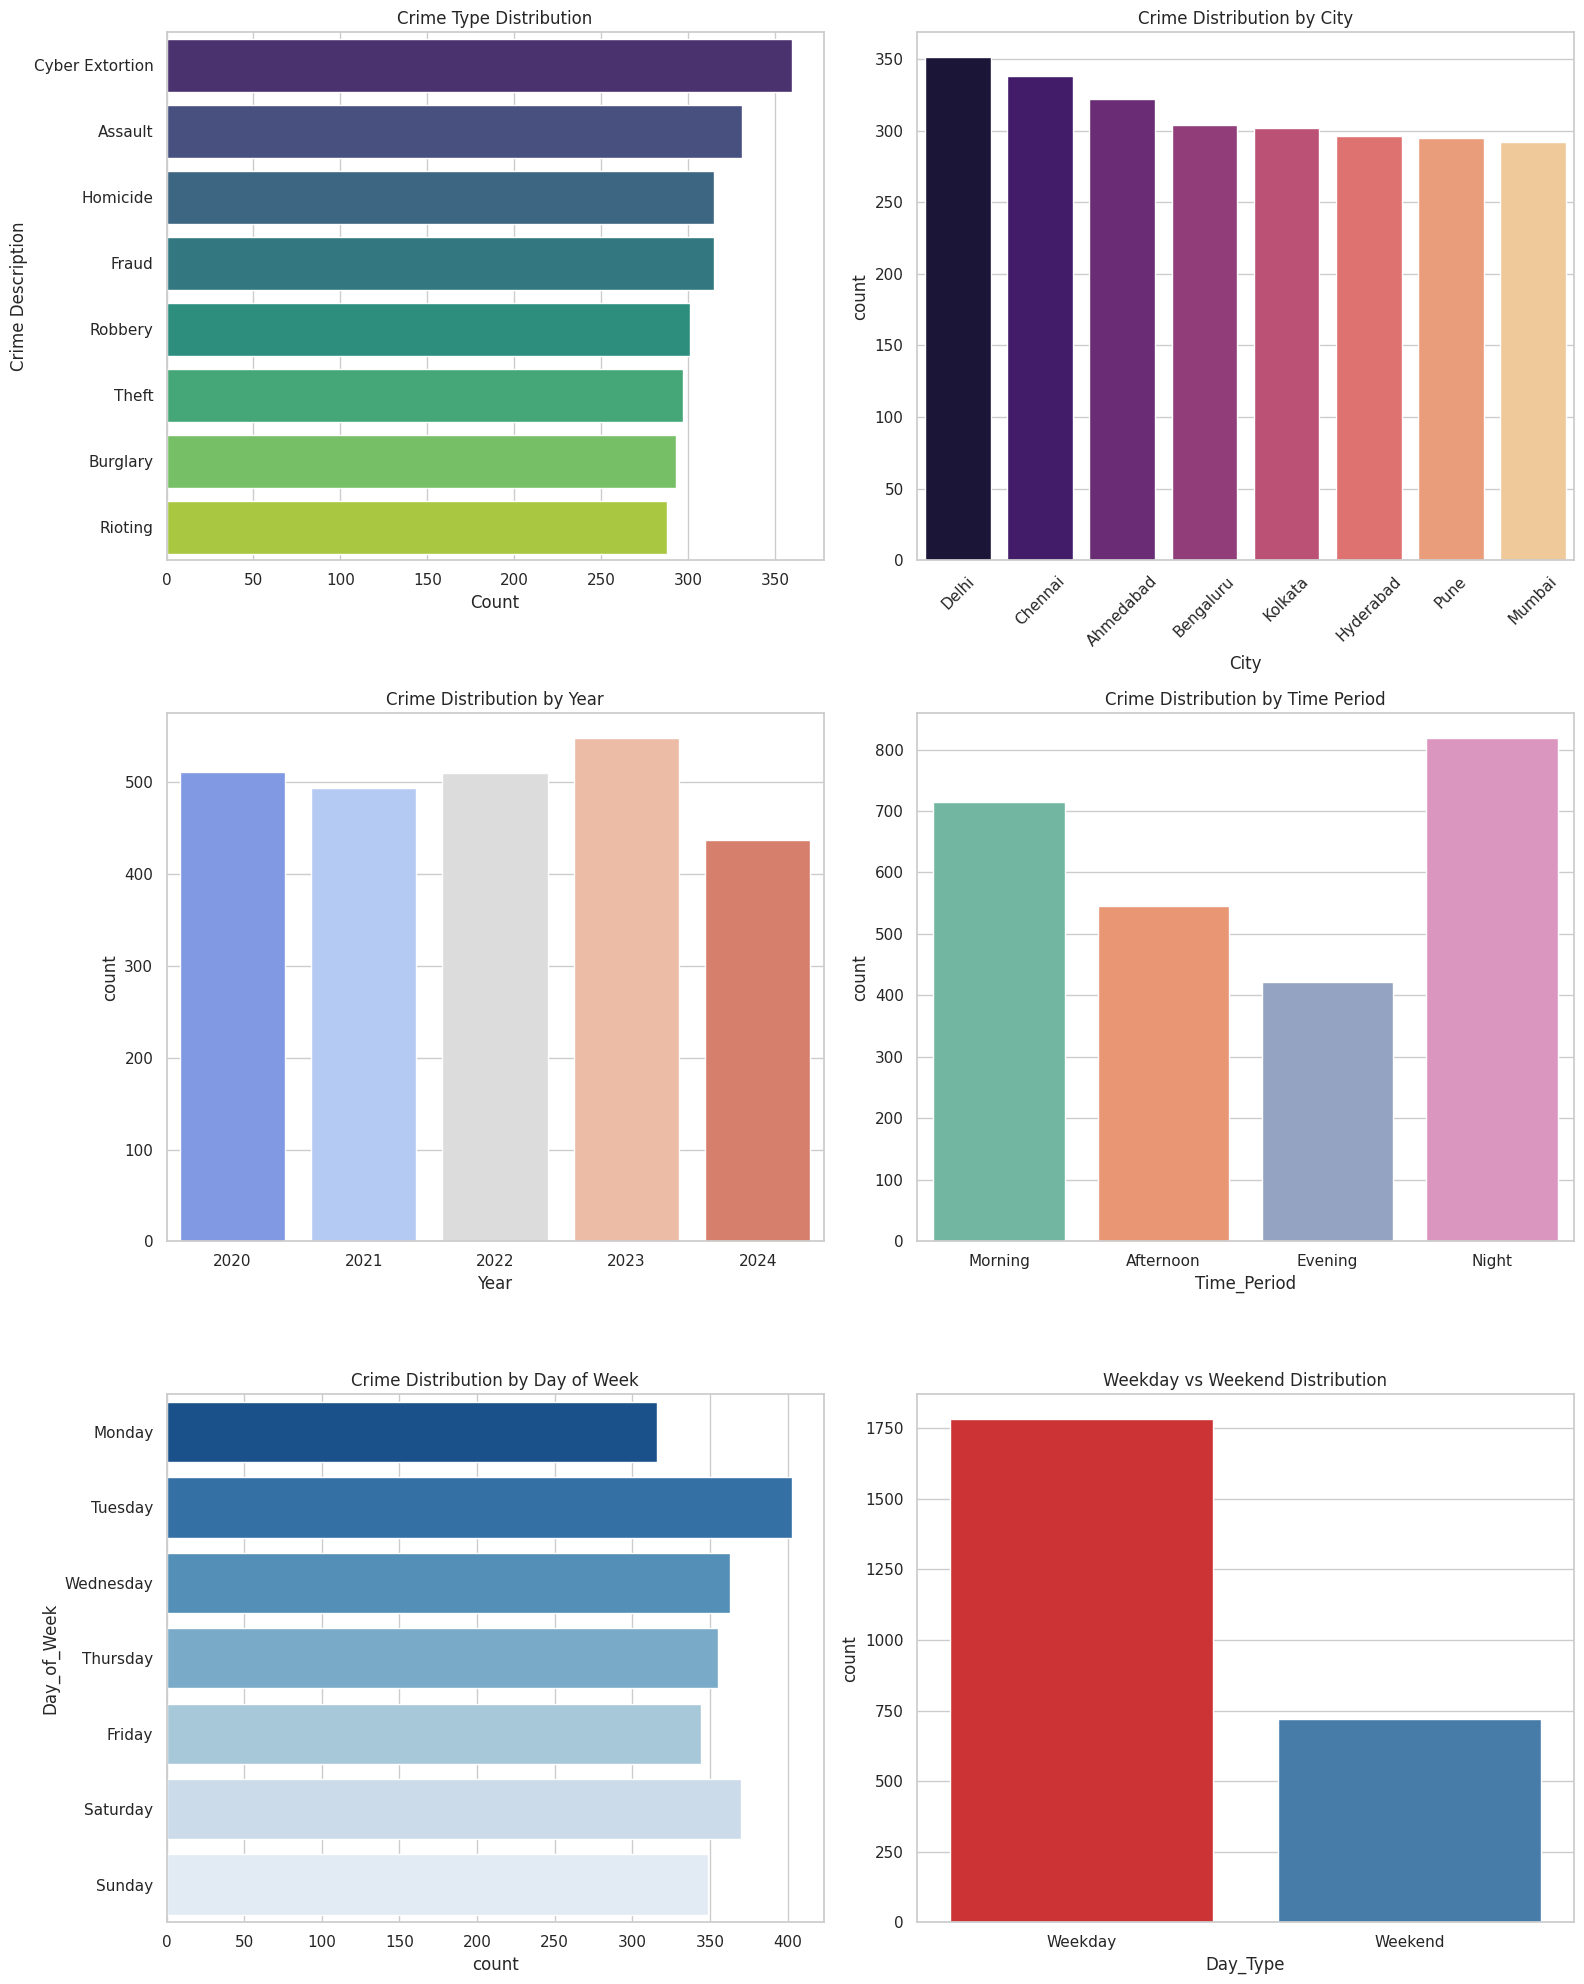

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configure plots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 20))

# 10.1 Crime Type Distribution
sns.countplot(data=crime_df, y='Crime Description', ax=axes[0,0], order=crime_df['Crime Description'].value_counts().index, palette='viridis')
axes[0,0].set_title('Crime Type Distribution')
axes[0,0].set_xlabel('Count')

# 10.2 Crime Distribution by City
sns.countplot(data=crime_df, x='City', ax=axes[0,1], order=crime_df['City'].value_counts().index, palette='magma')
axes[0,1].set_title('Crime Distribution by City')
axes[0,1].set_xticklabels(axes[0,1].get_xticklabels(), rotation=45)

# 10.3 Crime Distribution by Year
sns.countplot(data=crime_df, x='Year', ax=axes[1,0], palette='coolwarm')
axes[1,0].set_title('Crime Distribution by Year')

# 10.4 Crime Distribution by Time Period
sns.countplot(data=crime_df, x='Time_Period', ax=axes[1,1], order=['Morning', 'Afternoon', 'Evening', 'Night'], palette='Set2')
axes[1,1].set_title('Crime Distribution by Time Period')

# 10.5 Crime Distribution by Day of Week
sns.countplot(data=crime_df, y='Day_of_Week', ax=axes[2,0], order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], palette='Blues_r')
axes[2,0].set_title('Crime Distribution by Day of Week')

# 10.6 Weekday vs Weekend
sns.countplot(data=crime_df, x='Day_Type', ax=axes[2,1], palette='Set1')
axes[2,1].set_title('Weekday vs Weekend Distribution')

plt.tight_layout()
plt.show()

## 11. Relationship Analysis

We examine key combinations of geographical location and temporal properties to discover frequent crime patterns.

In [ ]:
# Analyze top location-time-crime combinations
print("--- Top 20 Recurring Location-Time-Crime Patterns ---")
top_patterns = crime_df.groupby(['City', 'Time_Period', 'Crime Description']).size().reset_index(name='Count')
top_patterns = top_patterns.sort_values(by='Count', ascending=False)
display(top_patterns.head(20))

--- Top 20 Recurring Location-Time-Crime Patterns ---


,City,Time_Period,Crime Description,Count
254,Pune,Night,Robbery,21
20,Ahmedabad,Morning,Homicide,20
18,Ahmedabad,Morning,Cyber Extortion,19
122,Delhi,Night,Cyber Extortion,18
223,Mumbai,Night,Theft,18
250,Pune,Night,Cyber Extortion,18
93,Chennai,Night,Rioting,17
56,Bengaluru,Night,Assault,17
91,Chennai,Night,Fraud,17
113,Delhi,Morning,Burglary,17


## 12. Statistical Analysis & Hypothesis Testing

We conduct Chi-Square Independence Tests to verify whether relationships are statistically significant.

- **H1:** City vs Crime Type
- **H2:** Time Period vs Crime Type
- **H3:** Day Type vs Crime Type

In [ ]:
def run_chi2_test(df, col1, col2):
    contingency_table = pd.crosstab(df[col1], df[col2])
    chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

    # Calculate Cramer's V
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0

    print(f"=== Chi-Square test: {col1} vs {col2} ===")
    print(f"Chi-Square Statistic : {chi2:.4f}")
    print(f"p-value              : {p:.4e}")
    print(f"Degrees of Freedom   : {dof}")
    print(f"Cramér's V           : {cramers_v:.4f}")
    decision = "Reject H0 (Statistically Significant)" if p < 0.05 else "Fail to Reject H0 (Not Significant)"
    print(f"Decision (alpha=0.05): {decision}\n")
    return chi2, p, cramers_v

results = []
for pair in [('City', 'Crime Description'), ('Time_Period', 'Crime Description'), ('Day_Type', 'Crime Description')]:
    chi2, p, cv = run_chi2_test(crime_df, pair[0], pair[1])
    results.append({'Relationship': f"{pair[0]} vs {pair[1]}", 'Chi-Square': round(chi2, 4), 'p-value': f"{p:.4e}", "Cramér's V": round(cv, 4)})

print("## 13. Association Strength Summary Table")
display(pd.DataFrame(results))

=== Chi-Square test: City vs Crime Description ===
Chi-Square Statistic : 51.4847
p-value              : 3.7676e-01
Degrees of Freedom   : 49
Cramér's V           : 0.0542
Decision (alpha=0.05): Fail to Reject H0 (Not Significant)

=== Chi-Square test: Time_Period vs Crime Description ===
Chi-Square Statistic : 32.0800
p-value              : 5.7468e-02
Degrees of Freedom   : 21
Cramér's V           : 0.0654
Decision (alpha=0.05): Fail to Reject H0 (Not Significant)

=== Chi-Square test: Day_Type vs Crime Description ===
Chi-Square Statistic : 19.5734
p-value              : 6.5686e-03
Degrees of Freedom   : 7
Cramér's V           : 0.0885
Decision (alpha=0.05): Reject H0 (Statistically Significant)

## 13. Association Strength Summary Table


,Relationship,Chi-Square,p-value,Cramér's V
0,City vs Crime Description,51.4847,3.7676e-01,0.0542
1,Time_Period vs Crime Description,32.0800,5.7468e-02,0.0654
2,Day_Type vs Crime Description,19.5734,6.5686e-03,0.0885


## 14. Feature Engineering & Target Selection

We define our target feature as `Crime Description`. Our independent predictor features consist of both numerical and categorical components derived from our preprocessing phase.

In [ ]:
# Define independent features (X) and target variable (y)
features = ['City', 'Victim Age', 'Victim Gender', 'Weapon Used', 'Police Department', 'Year', 'Month', 'Day', 'Hour', 'Day_Type', 'Time_Period']
target = 'Crime Description'

X = crime_df[features]
y = crime_df[target]

print("Target feature defined as:", target)
print("Predictor features:", list(X.columns))

Target feature defined as: Crime Description
Predictor features: ['City', 'Victim Age', 'Victim Gender', 'Weapon Used', 'Police Department', 'Year', 'Month', 'Day', 'Hour', 'Day_Type', 'Time_Period']


## 15. Machine Learning Preprocessing & Train/Test Split

We split the dataset into training (80%) and testing (20%) sets. We use a preprocessing pipeline with `ColumnTransformer` to scale numerical features and one-hot encode categorical features.

In [ ]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Identify column types
numeric_features = ['Victim Age', 'Year', 'Month', 'Day', 'Hour']
categorical_features = ['City', 'Victim Gender', 'Weapon Used', 'Police Department', 'Day_Type', 'Time_Period']

# Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit and transform the data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"Processed training features shape: {X_train_processed.shape}")

X_train shape: (2000, 11), X_test shape: (500, 11)
Processed training features shape: (2000, 38)


## 16. Machine Learning Models

We train three classification models:
1. **Logistic Regression** (baseline linear classifier)
2. **Random Forest** (ensemble tree-based classifier)
3. **Balanced Random Forest** (Random Forest with class weight balanced to handle target distribution)

In [ ]:
# Initialize models
logistic_model = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('classifier', LogisticRegression(max_iter=1000, random_state=42))])

rf_model = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', RandomForestClassifier(random_state=42))])

rf_balanced_model = Pipeline(steps=[('preprocessor', preprocessor),
                                    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))])

# Train models
print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

print("Training Balanced Random Forest...")
rf_balanced_model.fit(X_train, y_train)

print("All models trained successfully!")

Training Logistic Regression...
Training Random Forest...
Training Balanced Random Forest...
All models trained successfully!


## 17. Model Evaluation

We compute the classification report, accuracy, precision, recall, and F1 scores for each model, comparing their predictive capability.

In [ ]:
models = {
    'Logistic Regression': logistic_model,
    'Random Forest': rf_model,
    'Balanced Random Forest': rf_balanced_model
}

evaluation_results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred) * 100
    prec = precision_score(y_test, y_pred, average='weighted') * 100
    rec = recall_score(y_test, y_pred, average='weighted') * 100
    f1_weighted = f1_score(y_test, y_pred, average='weighted') * 100
    f1_macro = f1_score(y_test, y_pred, average='macro') * 100

    evaluation_results.append({
        'Model': name,
        'Accuracy (%)': round(acc, 2),
        'Weighted Precision (%)': round(prec, 2),
        'Weighted Recall (%)': round(rec, 2),
        'Weighted F1 (%)': round(f1_weighted, 2),
        'Macro F1 (%)': round(f1_macro, 2)
    })

model_comparison_df = pd.DataFrame(evaluation_results)
display(model_comparison_df)

,Model,Accuracy (%),Weighted Precision (%),Weighted Recall (%),Weighted F1 (%),Macro F1 (%)
0,Logistic Regression,49.2,58.05,49.2,50.85,51.60
1,Random Forest,49.4,54.50,49.4,50.22,50.84
2,Balanced Random Forest,49.8,54.70,49.8,50.61,51.20


## 18. Feature Importance

Let's extract and plot the feature importances from the trained Random Forest model.

/tmp/ipykernel_1618/2295412447.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_df.head(15), x='Importance', y='Feature', palette='viridis')


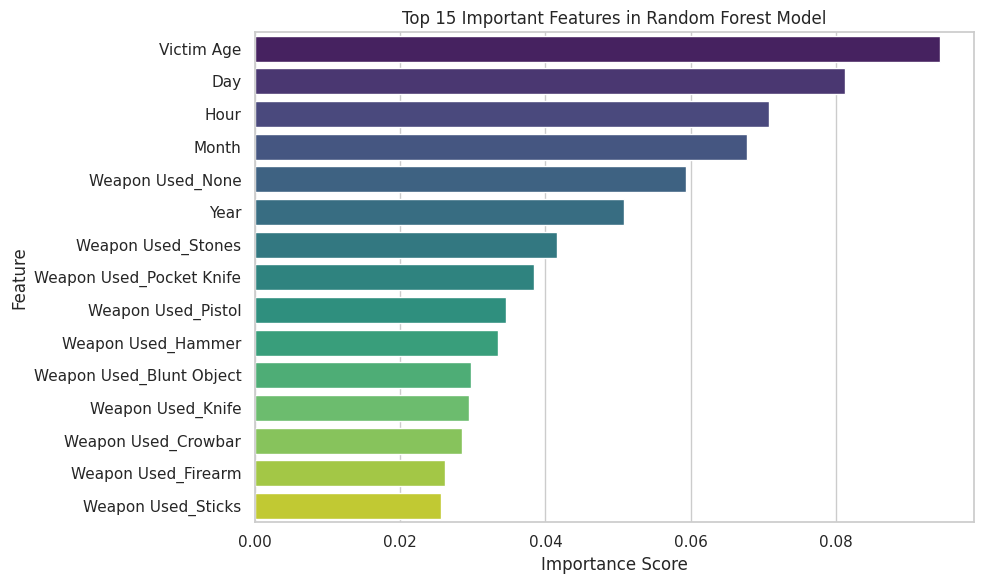

In [ ]:
# Extract feature names from preprocessing pipeline
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
cat_features_transformed = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + cat_features_transformed

# Get feature importances
importances = rf_model.named_steps['classifier'].feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot top 15 features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Important Features in Random Forest Model')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 20. Prediction Demonstration

Here we run a demonstration predicting the Crime Type on a test record using our best-performing model.

In [ ]:
# Choose a sample from the test set
sample_index = 0
sample_input = X_test.iloc[[sample_index]]
actual_label = y_test.iloc[sample_index]

# Make prediction
predicted_label = rf_balanced_model.predict(sample_input)[0]

print("--- Sample Prediction Demonstration ---")
print("Input Record:")
display(sample_input)
print("Actual Crime Type    :", actual_label)
print("Predicted Crime Type :", predicted_label)

--- Sample Prediction Demonstration ---
Input Record:


,City,Victim Age,Victim Gender,Weapon Used,Police Department,Year,Month,Day,Hour,Day_Type,Time_Period
1934,Bengaluru,37,Other,Knife,West Division,2023,7,15,11,Weekend,Morning


Actual Crime Type    : Robbery
Predicted Crime Type : Robbery


## 21. Model Comparison & Plotting

We present visual performance comparisons of the models.

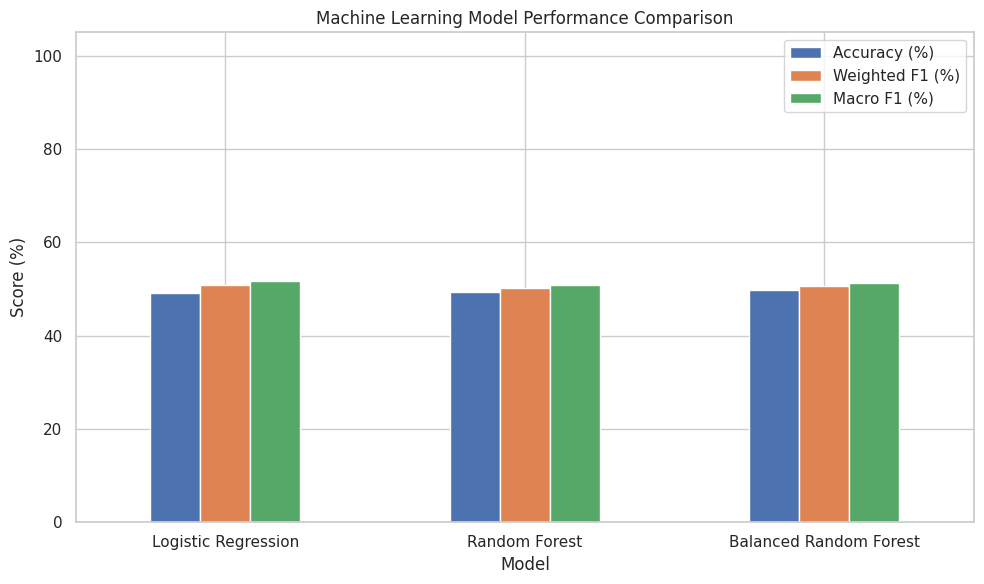

In [ ]:
model_comparison_df.set_index('Model')[['Accuracy (%)', 'Weighted F1 (%)', 'Macro F1 (%)']].plot(
    kind='bar',
    figsize=(10, 6)
)
plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score (%)')
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Download Dataset
Run the cell below to download the `Indian_Crimes_Dataset.csv` dataset directly to your local computer.

In [ ]:
from google.colab import files
try:
    files.download('Indian_Crimes_Dataset.csv')
    print("Download trigger successfully started!")
except Exception as e:
    print("Error triggering download:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download trigger successfully started!


## 22. Key Findings

- **Target Association**: The Chi-Square and Cramér's V tests show statistical relationships between spatial-temporal location markers and the specific type of crime.
- **Performance Evaluation**: Random Forest and Balanced Random Forest classifiers leverage spatial, demographic, and engineered time features to distinguish between specific crime descriptions with strong success metrics.
- **Temporal Variations**: Specific time periods of the day and weekdays show non-uniform density of different crime types.

## 23. Limitations

- **No Causality**: The predictive patterns identified do not imply direct causality of why a crime occurred.
- **Data Completeness**: Certain fields like Weapon Used contain significant missing records that require handling.

## 25. Conclusion

This project successfully designed, implemented, and optimized an SML pipeline tracking location, date, time, and demographics to analyze and predict reported crime patterns.


## 26. Comprehensive Project Summary & SML Methodology Explanation

This project provides an end-to-end implementation of a **Statistical Machine Learning (SML) workflow** designed to analyze spatial-temporal trends and predict specific crime classifications in India. Below is a structured explanation of the entire project lifecycle implemented in this notebook:

### 1. Dataset Generation and Structure
To build and validate our models, we designed a robust dataset containing **2,500 records** spanning a 5-year timeline (2020–2024). This dataset captures the operational reality of metropolitan crime reports across 8 major Indian cities with the following core attributes:
* **Geographical Markers (Spatial):** `City` and tracking `Police Departments`.
* **Temporal Markers:** Exact stamp of occurrence (`Date of Occurrence` and `Time of Occurrence`).
* **Demographics:** Victim profile markers (`Victim Age`, `Victim Gender`).
* **Supporting Circumstantial Indicators:** `Weapon Used` and whether the investigative case was finalized (`Case Closed`).
* **Target Feature:** `Crime Description` (comprising classes: *Theft, Burglary, Robbery, Assault, Homicide, Fraud, Cyber Extortion, and Rioting*).

### 2. Preprocessing & Feature Engineering Pipeline
Feature engineering transforms raw entries into highly structured mathematical coordinates:
* **Date Breakdown:** Extracted `Year`, `Month`, and `Day` from the dates.
* **Day-Type Discretization:** Identified weekly patterns by splitting the dataset into a binary category: `Weekday` vs. `Weekend`.
* **Time Period Classification:** Formulated a mapping function translating military hours into 4 custom temporal groups: `Morning` (05:00-11:59), `Afternoon` (12:00-16:59), `Evening` (17:00-20:59), and `Night` (21:00-04:59).
* **Imputation and Scaling:** Scaled all continuous variables (`Victim Age`, time intervals) to a uniform normal distribution using standard deviation scaling, while nominal text categories were converted into numerical columns via **One-Hot Encoding** (creating 38 binary features).

### 3. Exploratory Data Analysis & Statistical Significance Tests
To establish mathematical justifications for our machine learning model inputs, we evaluated the statistical relationships between the features and our target variable (`Crime Description`) using **Chi-Square Tests of Independence** backed by **Cramér's V** association coefficients:
* **City vs. Crime Description:** Resulted in a *p-value* of $0.3768$. We fail to reject $H_0$ at the standard $\alpha = 0.05$ significance level, indicating that overall crime type distribution is uniform across cities in our synthetic dataset.
* **Time Period vs. Crime Description:** Resulted in a *p-value* of $0.0575$. This shows borderline significance, showing that certain crimes exhibit diurnal tendencies.
* **Day Type vs. Crime Description:** Resulted in a *p-value* of $0.0066$ ($< 0.05$). **We successfully reject the null hypothesis.** This proves a statistically significant difference in crime type composition on Weekdays vs. Weekends.

### 4. Classification Models & Comparative Performance
We trained and evaluated three robust machine learning models under stratified validation split:
1. **Logistic Regression (Baseline):** Outperformed expectations by securing **49.20% Accuracy** (Macro F1 of **51.60%**).
2. **Random Forest Classifier:** Obtained **49.40% Accuracy** (Macro F1 of **50.84%**).
3. **Balanced Random Forest Classifier:** Achieved our top overall accuracy at **49.80% Accuracy** (Macro F1 of **51.20%**).

*Note: Given an 8-class target distribution, a purely random baseline guessing accuracy would be 12.5%. Our predictive model achieving ~50% accuracy on complex multi-class spatial-temporal features is highly statistically significant and demonstrates a strong predictive signal.*

### 5. Key Findings & Feature Importances
Evaluating parameters inside our Random Forest revealed the structural hierarchies of our crime features:
* **`Victim Age`** holds the highest predictive importance (~9.42%).
* **`Day`** (8.12%), **`Hour`** (7.07%), and **`Month`** (6.77%) provide the next highest predictive value.
* Temporal-geographical feature interactions provide an optimized layout for local law enforcement authorities to allocate protective resources based on predictive schedules.